# LLM Hallucination Detection using HaluEval
## Model Evaluation, Results and Analysis

### Objective
This notebook evaluates the two trained classifiers on the held-out test set, compares their performance, analyses their errors, and selects the best model.

Model  Saved file:

TF-IDF + Logistic Regression (best_logistic_regression_model.pkl)
 TF-IDF + LinearSVC (SVM)
 (best_svm_pipeline.pkl)

### Evaluation setup
- **Test data:** `halu_test.csv` contains 4,000 instances (2,000 questions with two candidate answers each). It was separated from the training data before restructuring and was not used for training or hyperparameter tuning.
- **Positive class:** Hallucinated (1), since the goal of the project is to detect hallucinated answers.
- **Metrics:** Accuracy, Precision, Recall and F1-score, as stated in the project proposal. ROC-AUC is added as a threshold-independent measure.
- **No re-training:** The saved pipelines are used as they are, so the test set is used only once for the final evaluation.

### Contents
1. Environment setup and data loading
2. Predictions
3. Performance metrics
4. Confusion matrices
5. Comparison charts
6. Statistical comparison of the models
7. Error analysis
8. Best-model selection
9. Saving the results
10. Conclusion

## 1. Environment Setup and Data Loading

The saved pipelines were trained with scikit-learn 1.6.1. To avoid version incompatibilities when unpickling them, the same version is installed first. If Colab asks to restart the runtime after the installation, restart it and continue from the next cell.

In [3]:
!pip install -q scikit-learn==1.6.1

In [4]:
import os
import shutil

import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt

from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score
)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
CLASS_NAMES = ["Faithful (0)", "Hallucinated (1)"]

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


Three files are required: the test set and the two saved pipelines. They are uploaded manually, and two folders are created for the tables and figures produced later.

In [6]:
from google.colab import files

uploaded = files.upload()

TEST_CSV = "halu_test.csv"
LR_MODEL_FILE = "best_logistic_regression_model.pkl"
SVM_MODEL_FILE = "best_svm_pipeline.pkl"

RESULTS_DIR = "results"
TABLES_DIR = os.path.join(RESULTS_DIR, "tables")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

Saving best_svm_pipeline.pkl to best_svm_pipeline.pkl
Saving halu_test.csv to halu_test.csv
Saving best_logistic_regression_model.pkl to best_logistic_regression_model.pkl


### 1.1 Test set
The test set is inspected for missing values and class balance. Since every question should have exactly one faithful and one hallucinated answer, this structure is also verified because it is used in the error analysis.

In [8]:
test_data = pd.read_csv(TEST_CSV)

print("Test shape:", test_data.shape)
print("Columns:", test_data.columns.tolist())
print("\nMissing values:\n", test_data.isna().sum())

print("\nLabel counts:")
print(test_data["label"].value_counts().sort_index())

records_per_question = test_data["question"].value_counts()
labels_per_question = test_data.groupby("question")["label"].agg(set)

assert set(test_data["label"].unique()) == {0, 1}
assert records_per_question.eq(2).all()
assert labels_per_question.apply(lambda s: s == {0, 1}).all()

print("\nUnique questions:", test_data["question"].nunique())
print("Structure checks passed.")

Test shape: (4000, 5)
Columns: ['knowledge', 'question', 'answer', 'label', 'text']

Missing values:
 knowledge    0
question     0
answer       0
label        0
text         0
dtype: int64

Label counts:
label
0    2000
1    2000
Name: count, dtype: int64

Unique questions: 2000
Structure checks passed.


### 1.2 Saved models
Each file contains a complete pipeline (TF-IDF vectorizer followed by the classifier), so raw text can be passed to it directly.

In [9]:
models = {
    "Logistic Regression": joblib.load(LR_MODEL_FILE),
    "SVM (LinearSVC)": joblib.load(SVM_MODEL_FILE),
}

KEY = {"Logistic Regression": "lr", "SVM (LinearSVC)": "svm"}
COLORS = {"Logistic Regression": "#4C72B0", "SVM (LinearSVC)": "#DD8452"}

for name, model in models.items():
    print(f"{name}:")
    for step_name, step in model.steps:
        print(f"   {step_name}: {step}")

Logistic Regression:
   tfidf: TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
   logreg: LogisticRegression(C=10, max_iter=1000, random_state=42)
SVM (LinearSVC):
   tfidf: TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
   svm: LinearSVC(max_iter=5000, random_state=42)


## 2. Predictions

Both pipelines predict the class labels of the test set. A continuous score is also extracted for the ROC analysis: the predicted probability of the Hallucinated class for Logistic Regression, and the signed distance to the decision boundary for LinearSVC, which does not output probabilities.

In [10]:
X_test = test_data["text"]
y_test = test_data["label"].to_numpy()

preds, scores = {}, {}

for name, model in models.items():
    preds[name] = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        scores[name] = model.predict_proba(X_test)[:, 1]
    else:
        scores[name] = model.decision_function(X_test)

    print(f"{name}: predicted hallucinated = {(preds[name] == 1).sum()}, "
          f"predicted faithful = {(preds[name] == 0).sum()}")

Logistic Regression: predicted hallucinated = 1775, predicted faithful = 2225
SVM (LinearSVC): predicted hallucinated = 1769, predicted faithful = 2231


## 3. Performance Metrics

Accuracy, Precision, Recall and F1-score are computed for each model, with Hallucinated (1) as the positive class. Precision is the share of flagged answers that are truly hallucinated, and Recall is the share of hallucinated answers that are detected.

In [11]:
rows = []
for name, p in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, pos_label=1),
        "Recall": recall_score(y_test, p, pos_label=1),
        "F1-score": f1_score(y_test, p, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test, scores[name]),
    })

results = pd.DataFrame(rows).set_index("Model")

print("Table 1. Test-set performance (positive class = Hallucinated)")
display(results.round(4))

Table 1. Test-set performance (positive class = Hallucinated)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7292,0.7583,0.6730,0.7131,0.8067
SVM (LinearSVC),0.7312,0.7614,0.6735,0.7148,0.8076


The per-class reports show whether each model treats the two classes differently.

In [12]:
for name, p in preds.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, p, target_names=CLASS_NAMES, digits=4))

Logistic Regression
                  precision    recall  f1-score   support

    Faithful (0)     0.7061    0.7855    0.7437      2000
Hallucinated (1)     0.7583    0.6730    0.7131      2000

        accuracy                         0.7292      4000
       macro avg     0.7322    0.7292    0.7284      4000
    weighted avg     0.7322    0.7292    0.7284      4000

SVM (LinearSVC)
                  precision    recall  f1-score   support

    Faithful (0)     0.7073    0.7890    0.7459      2000
Hallucinated (1)     0.7614    0.6735    0.7148      2000

        accuracy                         0.7312      4000
       macro avg     0.7344    0.7312    0.7304      4000
    weighted avg     0.7344    0.7312    0.7304      4000



The test F1-score is compared with the mean cross-validation F1-score obtained by Students 1 and 2 on the training data. A small difference indicates that the validation estimate generalised to unseen data.

In [13]:
validation_f1 = {"Logistic Regression": 0.7182, "SVM (LinearSVC)": 0.7194}

generalisation = pd.DataFrame({
    "Validation F1 (CV)": pd.Series(validation_f1),
    "Test F1": results["F1-score"],
})
generalisation["Difference (Test - CV)"] = generalisation["Test F1"] - generalisation["Validation F1 (CV)"]

print("Table 2. Cross-validation F1 versus test F1")
display(generalisation.round(4))

Table 2. Cross-validation F1 versus test F1


,Validation F1 (CV),Test F1,Difference (Test - CV)
Logistic Regression,0.7182,0.7131,-0.0051
SVM (LinearSVC),0.7194,0.7148,-0.0046


In [14]:
ranked = results.sort_values(["F1-score", "Recall"], ascending=False)
best_model_name = ranked.index[0]
other_model_name = ranked.index[1]

print("Highest test F1:", best_model_name)

Highest test F1: SVM (LinearSVC)


## 4. Confusion Matrices

Each matrix shows the true class in the rows and the predicted class in the columns. A false positive (FP) is a faithful answer wrongly flagged as hallucinated, and a false negative (FN) is a hallucinated answer that was missed. The counts are shown first, followed by row-normalised percentages.

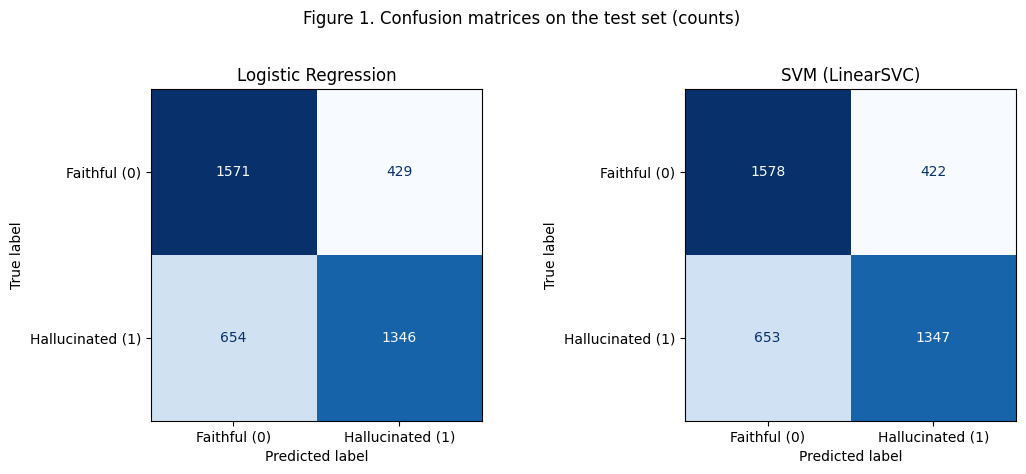

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Figure 1. Confusion matrices on the test set (counts)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_counts.png"), dpi=200, bbox_inches="tight")
plt.show()

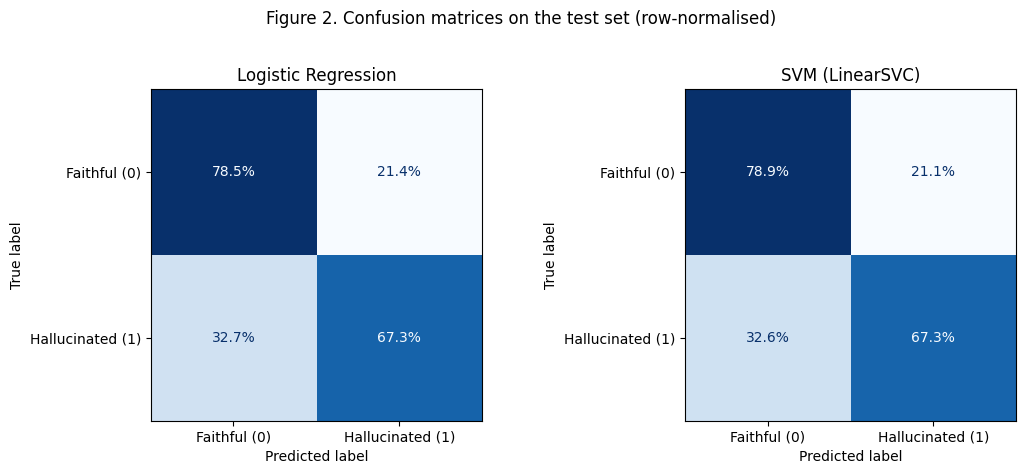

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

for ax, (name, p) in zip(axes, preds.items()):
    cm_norm = confusion_matrix(y_test, p, labels=[0, 1], normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".1%"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Figure 2. Confusion matrices on the test set (row-normalised)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_normalized.png"), dpi=200, bbox_inches="tight")
plt.show()

In [17]:
cm_rows = []
for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0, 1]).ravel()
    cm_rows.append({
        "Model": name,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "False positive rate": fp / (fp + tn),
        "False negative rate": fn / (fn + tp),
        "Total errors": fp + fn,
    })

cm_table = pd.DataFrame(cm_rows).set_index("Model")

print("Table 3. Confusion matrix values and error rates")
display(cm_table.round(4))

Table 3. Confusion matrix values and error rates


,TN,FP,FN,TP,False positive rate,False negative rate,Total errors
Model,,,,,,,
Logistic Regression,1571,429,654,1346,0.2145,0.3270,1083
SVM (LinearSVC),1578,422,653,1347,0.2110,0.3265,1075


## 5. Comparison Charts

The metrics of the two models are compared in a bar chart, with the 0.5 chance level of the balanced test set as a reference. The ROC curves then show the trade-off between the true positive rate and the false positive rate across all decision thresholds.

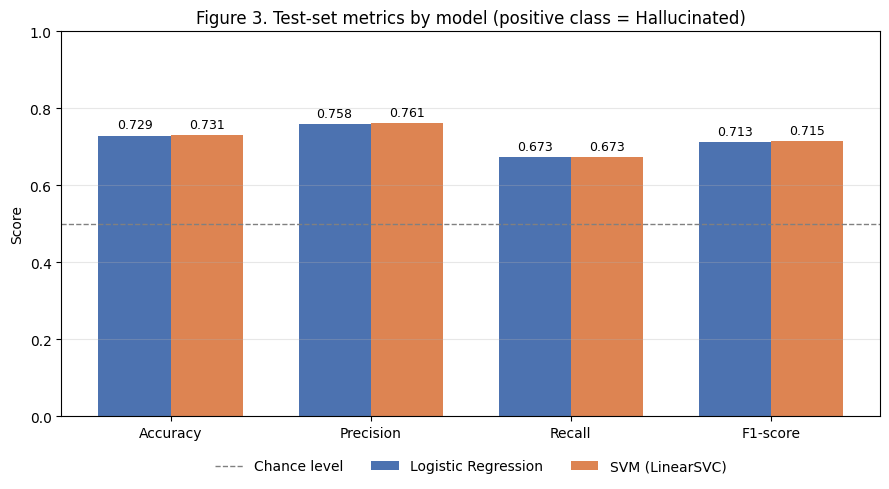

In [18]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metric_names))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5))

for i, name in enumerate(results.index):
    values = results.loc[name, metric_names].to_numpy()
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=name, color=COLORS[name])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, fontsize=9)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Chance level")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Figure 3. Test-set metrics by model (positive class = Hallucinated)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "metrics_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

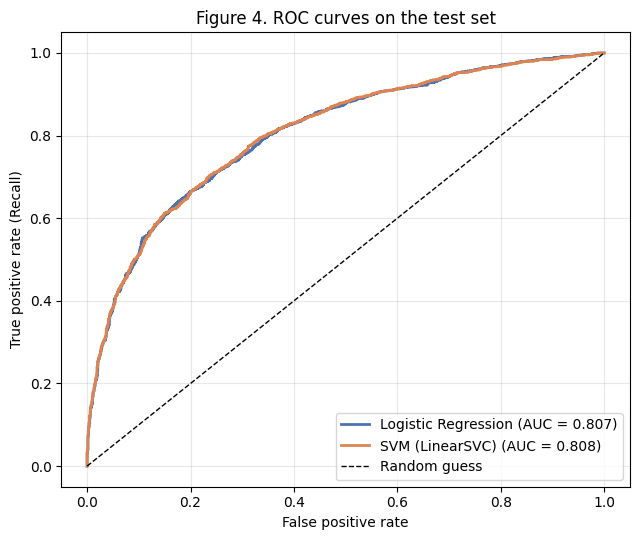

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})",
            color=COLORS[name], linewidth=2)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (Recall)")
ax.set_title("Figure 4. ROC curves on the test set")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "roc_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

## 6. Statistical Comparison of the Models

The two models obtain very similar scores, so we test whether the observed difference is larger than what could be expected from chance on a finite test set. Two complementary methods are used:

1. **McNemar's exact test** compares the models on the same instances and uses only the cases where exactly one model is correct. The null hypothesis is that both models have the same error rate.
2. **Question-level bootstrap** resamples the 2,000 test questions with replacement (keeping both answers of a question together) 2,000 times. This gives 95% confidence intervals for each metric and for the difference between the models.

First, the predictions are collected in one table that is also used in the error analysis, and McNemar's test is applied.

In [20]:
analysis = test_data.copy()
analysis["answer_words"] = analysis["answer"].str.split().str.len()
analysis["knowledge_words"] = analysis["knowledge"].str.split().str.len()

for name in models:
    k = KEY[name]
    analysis[f"pred_{k}"] = preds[name]
    analysis[f"score_{k}"] = scores[name]
    analysis[f"correct_{k}"] = (preds[name] == y_test)

only_lr_correct = int((analysis["correct_lr"] & ~analysis["correct_svm"]).sum())
only_svm_correct = int((~analysis["correct_lr"] & analysis["correct_svm"]).sum())
n_discordant = only_lr_correct + only_svm_correct

mcnemar_p = binomtest(min(only_lr_correct, only_svm_correct), n_discordant, 0.5).pvalue

print("Instances where only Logistic Regression is correct:", only_lr_correct)
print("Instances where only SVM is correct:               ", only_svm_correct)
print(f"McNemar exact test p-value: {mcnemar_p:.4f}")
print("Significant at 0.05" if mcnemar_p < 0.05 else "Not significant at 0.05")

Instances where only Logistic Regression is correct: 36
Instances where only SVM is correct:                44
McNemar exact test p-value: 0.4340
Not significant at 0.05


The bootstrap is then performed. The number of true positives, false positives, false negatives and correct predictions is first counted per question, so that each resample only requires summing these counts.

In [21]:
y_s = analysis["label"]
per_q = {}
for name in models:
    k = KEY[name]
    p_s = analysis[f"pred_{k}"]
    tmp = pd.DataFrame({
        "question": analysis["question"],
        "tp": ((y_s == 1) & (p_s == 1)).astype(int),
        "fp": ((y_s == 0) & (p_s == 1)).astype(int),
        "fn": ((y_s == 1) & (p_s == 0)).astype(int),
        "ok": (y_s == p_s).astype(int),
        "n": 1,
    })
    per_q[name] = tmp.groupby("question").sum()

questions = per_q["Logistic Regression"].index
assert all((per_q[n].index == questions).all() for n in per_q)

def metrics_from_counts(c):
    tp, fp, fn, ok, n = c["tp"], c["fp"], c["fn"], c["ok"], c["n"]
    return {
        "Accuracy": ok / n,
        "Precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "Recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "F1-score": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
    }

rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 2000
count_names = ["tp", "fp", "fn", "ok", "n"]
arrays = {name: per_q[name][count_names].to_numpy() for name in models}
boot = {name: [] for name in models}

for _ in range(N_BOOT):
    idx = rng.integers(0, len(questions), len(questions))
    for name in models:
        sums = arrays[name][idx].sum(axis=0)
        boot[name].append(metrics_from_counts(dict(zip(count_names, sums))))

boot = {name: pd.DataFrame(v) for name, v in boot.items()}

In [22]:
ci_rows = []
for name in models:
    for m in ["Accuracy", "Precision", "Recall", "F1-score"]:
        lo, hi = np.percentile(boot[name][m], [2.5, 97.5])
        ci_rows.append({"Model": name, "Metric": m, "Test value": results.loc[name, m],
                        "95% CI low": lo, "95% CI high": hi})
ci_table = pd.DataFrame(ci_rows)

print("Table 4. Test metrics with 95% bootstrap confidence intervals")
display(ci_table.round(4))

diff_rows = []
for m in ["Accuracy", "Precision", "Recall", "F1-score"]:
    d = boot["SVM (LinearSVC)"][m] - boot["Logistic Regression"][m]
    lo, hi = np.percentile(d, [2.5, 97.5])
    diff_rows.append({
        "Metric": m,
        "SVM - LR (test)": results.loc["SVM (LinearSVC)", m] - results.loc["Logistic Regression", m],
        "95% CI low": lo, "95% CI high": hi,
        "CI contains 0": bool(lo <= 0 <= hi),
    })
diff_table = pd.DataFrame(diff_rows)

print("\nTable 5. Difference between the models (SVM minus Logistic Regression)")
display(diff_table.round(4))

Table 4. Test metrics with 95% bootstrap confidence intervals


,Model,Metric,Test value,95% CI low,95% CI high
0,Logistic Regression,Accuracy,0.7292,0.7180,0.7410
1,Logistic Regression,Precision,0.7583,0.7437,0.7733
2,Logistic Regression,Recall,0.6730,0.6525,0.6940
3,Logistic Regression,F1-score,0.7131,0.6996,0.7267
4,SVM (LinearSVC),Accuracy,0.7312,0.7198,0.7428
5,SVM (LinearSVC),Precision,0.7614,0.7467,0.7768
6,SVM (LinearSVC),Recall,0.6735,0.6525,0.6940
7,SVM (LinearSVC),F1-score,0.7148,0.7011,0.7285



Table 5. Difference between the models (SVM minus Logistic Regression)


,Metric,SVM - LR (test),95% CI low,95% CI high,CI contains 0
0,Accuracy,0.0020,-0.0022,0.0063,True
1,Precision,0.0031,-0.0024,0.0086,True
2,Recall,0.0005,-0.0060,0.0070,True
3,F1-score,0.0017,-0.0032,0.0064,True


## 7. Error Analysis

This section examines where and why the models fail: the agreement between the models, the behaviour at the question level, and the effect of answer length and question type.

### 7.1 Agreement between the models

In [23]:
agreement = pd.Series({
    "Both correct": int((analysis["correct_lr"] & analysis["correct_svm"]).sum()),
    "Both wrong": int((~analysis["correct_lr"] & ~analysis["correct_svm"]).sum()),
    "Only Logistic Regression correct": only_lr_correct,
    "Only SVM correct": only_svm_correct,
}, name="Instances")

agreement_table = agreement.to_frame()
agreement_table["Share of test set"] = agreement_table["Instances"] / len(analysis)

print("Table 6. Agreement between the two models")
display(agreement_table.round(4))

Table 6. Agreement between the two models


,Instances,Share of test set
Both correct,2881,0.7202
Both wrong,1039,0.2598
Only Logistic Regression correct,36,0.0090
Only SVM correct,44,0.0110


### 7.2 Question-level analysis

Each test question has one faithful and one hallucinated answer, which allows two additional checks:

- **Outcome per question:** whether both answers are classified correctly, both are flagged as hallucinated, both are accepted as faithful, or the two labels are swapped.
- **Pairwise ranking accuracy:** the proportion of questions in which the hallucinated answer receives a higher score than the faithful answer. It measures whether the model orders the two answers correctly even when the decision threshold fails.

The pairwise comparison uses the other answer of the same question, which is not available in a real deployment. It is therefore used only as a diagnostic.

In [24]:
pair_rows = []
rank_rows = []

for name in models:
    k = KEY[name]
    piv = analysis.pivot(index="question", columns="label", values=[f"pred_{k}", f"score_{k}"])

    pred_h, pred_f = piv[(f"pred_{k}", 1)], piv[(f"pred_{k}", 0)]
    score_h, score_f = piv[(f"score_{k}", 1)], piv[(f"score_{k}", 0)]

    n_q = len(piv)
    pair_rows.append({
        "Model": name,
        "Both right": ((pred_h == 1) & (pred_f == 0)).sum() / n_q,
        "Both flagged hallucinated": ((pred_h == 1) & (pred_f == 1)).sum() / n_q,
        "Both accepted as faithful": ((pred_h == 0) & (pred_f == 0)).sum() / n_q,
        "Swapped": ((pred_h == 0) & (pred_f == 1)).sum() / n_q,
    })
    rank_rows.append({
        "Model": name,
        "Pairwise ranking accuracy": (score_h > score_f).mean(),
    })

pair_table = pd.DataFrame(pair_rows).set_index("Model")
rank_table = pd.DataFrame(rank_rows).set_index("Model")

print("Table 7. Outcome per question (share of the 2,000 test questions)")
display(pair_table.round(4))

print("\nTable 8. Pairwise ranking accuracy")
display(rank_table.round(4))

Table 7. Outcome per question (share of the 2,000 test questions)


,Both right,Both flagged hallucinated,Both accepted as faithful,Swapped
Model,,,,
Logistic Regression,0.4740,0.199,0.3115,0.0155
SVM (LinearSVC),0.4775,0.196,0.3115,0.0150



Table 8. Pairwise ranking accuracy


,Pairwise ranking accuracy
Model,
Logistic Regression,0.9155
SVM (LinearSVC),0.9185


### 7.3 Effect of answer length

The word counts of the answers are compared across the two classes. The error rate and the share of answers flagged as hallucinated are then reported for five answer-length groups (quintiles).

In [25]:
print("Average length in words, by true label:")
display(analysis.groupby("label")[["answer_words", "knowledge_words"]].agg(["mean", "median"]).round(1))

len_piv = analysis.pivot(index="question", columns="label", values="answer_words")
longer = (len_piv[1] > len_piv[0]).mean()
equal = (len_piv[1] == len_piv[0]).mean()
shorter = (len_piv[1] < len_piv[0]).mean()
print(f"\nPer question, the hallucinated answer is longer than the faithful one in {longer:.1%} of questions "
      f"(equal length: {equal:.1%}, shorter: {shorter:.1%}).")

analysis["answer_len_bin"] = pd.qcut(analysis["answer_words"], 5, duplicates="drop")

length_table = analysis.groupby("answer_len_bin", observed=True).apply(
    lambda g: pd.Series({
        "Instances": len(g),
        "True hallucinated (%)": 100 * g["label"].mean(),
        "LR error rate (%)": 100 * (1 - g["correct_lr"].mean()),
        "SVM error rate (%)": 100 * (1 - g["correct_svm"].mean()),
        "LR flagged hallucinated (%)": 100 * g["pred_lr"].mean(),
        "SVM flagged hallucinated (%)": 100 * g["pred_svm"].mean(),
    }),
    include_groups=False,
)
length_table.index = length_table.index.astype(str)
length_table.index.name = "Answer length (words)"

print("\nTable 9. Errors by answer length (quintiles)")
display(length_table.round(1))

Average length in words, by true label:


answer_words        knowledge_words       
              mean median            mean median
label                                           
0              2.3    2.0            55.0   51.0
1             10.9    9.0            55.0   51.0


Per question, the hallucinated answer is longer than the faithful one in 96.5% of questions (equal length: 2.4%, shorter: 1.1%).

Table 9. Errors by answer length (quintiles)


,Instances,True hallucinated (%),LR error rate (%),SVM error rate (%),LR flagged hallucinated (%),SVM flagged hallucinated (%)
Answer length (words),,,,,,
"(0.999, 2.0]",1435.0,3.3,21.3,20.7,20.1,19.4
"(2.0, 3.0]",411.0,5.8,23.8,23.8,24.8,24.8
"(3.0, 6.0]",659.0,70.0,40.5,41.0,47.3,47.5
"(6.0, 11.0]",735.0,98.1,31.7,31.3,68.0,68.4
"(11.0, 81.0]",760.0,98.2,23.6,23.7,75.4,75.3


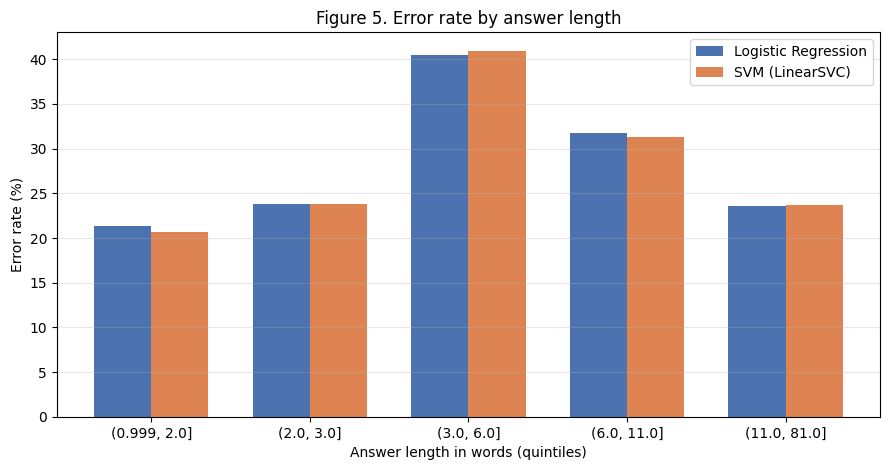

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.8))

bins = length_table.index
x = np.arange(len(bins))
w = 0.36

ax.bar(x - w / 2, length_table["LR error rate (%)"], w, label="Logistic Regression", color=COLORS["Logistic Regression"])
ax.bar(x + w / 2, length_table["SVM error rate (%)"], w, label="SVM (LinearSVC)", color=COLORS["SVM (LinearSVC)"])

ax.set_xticks(x)
ax.set_xticklabels(bins)
ax.set_xlabel("Answer length in words (quintiles)")
ax.set_ylabel("Error rate (%)")
ax.set_title("Figure 5. Error rate by answer length")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "error_rate_by_answer_length.png"), dpi=200, bbox_inches="tight")
plt.show()

### 7.4 Effect of question type

Questions are grouped by their first word (who, what, which, etc.). Questions that start with other words, such as yes/no questions, are grouped together.

In [27]:
def question_type(q):
    words = q.strip().lower().split()
    first = words[0] if words else ""
    for t in ["who", "what", "when", "where", "which", "how", "why"]:
        if first.startswith(t):
            return t
    return "other (yes/no, etc.)"

analysis["question_type"] = analysis["question"].apply(question_type)

qtype_table = analysis.groupby("question_type").apply(
    lambda g: pd.Series({
        "Instances": len(g),
        "LR error rate (%)": 100 * (1 - g["correct_lr"].mean()),
        "SVM error rate (%)": 100 * (1 - g["correct_svm"].mean()),
    }),
    include_groups=False,
).sort_values("Instances", ascending=False)
qtype_table["Instances"] = qtype_table["Instances"].astype(int)

print("Table 10. Errors by question type")
display(qtype_table.round(1))

Table 10. Errors by question type


,Instances,LR error rate (%),SVM error rate (%)
question_type,,,
"other (yes/no, etc.)",1952,26.7,26.9
what,926,27.1,26.5
which,512,32.0,31.1
who,336,25.3,25.0
when,116,20.7,20.7
where,88,18.2,19.3
how,70,30.0,30.0


### 7.5 Examples of misclassified answers

Random false negatives and false positives of the model with the highest test F1 are displayed to give a qualitative view of the errors.

In [28]:
k = KEY[best_model_name]

false_negatives = analysis[(analysis["label"] == 1) & (analysis[f"pred_{k}"] == 0)]
false_positives = analysis[(analysis["label"] == 0) & (analysis[f"pred_{k}"] == 1)]

def show_examples(df, title, n=4):
    print("=" * 90)
    print(f"{title} ({best_model_name}) - showing {n} of {len(df)}")
    print("=" * 90)
    for _, r in df.sample(n, random_state=RANDOM_STATE).iterrows():
        print(f"Question : {r['question'][:200]}")
        print(f"Answer   : {r['answer'][:200]}")
        print(f"Knowledge: {r['knowledge'][:250]}...")
        print(f"Model score: {r[f'score_{k}']:.3f}")
        print("-" * 90)

show_examples(false_negatives, "FALSE NEGATIVES: hallucinated answers accepted as faithful")
show_examples(false_positives, "FALSE POSITIVES: faithful answers flagged as hallucinated")

FALSE NEGATIVES: hallucinated answers accepted as faithful (SVM (LinearSVC)) - showing 4 of 653
Question : Tjeerd Eize Korf, a Dutch professional footballer from Flevoland, is the twelfth province of what country?
Answer   : Tjeerd Eize Korf, a Dutch professional footballer from Flevoland, is part of Germany.
Knowledge: Tjeerd Eize Korf (born 11 May 1983 in Emmeloord, Flevoland) is a Dutch professional footballer who currently plays as a striker for BV Veendam.Flevoland (] ) is the twelfth province of the Netherlands....
Model score: -0.024
------------------------------------------------------------------------------------------
Question : Which role did the only non-American from Pajama Party originate in the Broadway musical "Rent"?
Answer   : Daphne Rubin-Vega originated the role of Lucy.
Knowledge: Pajama Party was an American female vocal trio from Brooklyn, New York active between 1988 and 1992. The members were Jennifer McQuilkin of New Jersey, Daphne Rubin-Vega of Panama, and 

A simple lexical check follows: the share of answer words that also appear in the knowledge text. It indicates whether faithful and hallucinated answers differ in how much they overlap with the source, which TF-IDF over the concatenated text does not model explicitly.

In [29]:
def overlap_ratio(row):
    ans = set(row["answer"].lower().split())
    kn = set(row["knowledge"].lower().split())
    return len(ans & kn) / len(ans) if ans else 0.0

analysis["answer_in_knowledge"] = analysis.apply(overlap_ratio, axis=1)

print("Share of answer words that also appear in the knowledge, by true label:")
display(analysis.groupby("label")["answer_in_knowledge"].agg(["mean", "median"]).round(3))

print("\nSame measure for correct and wrong predictions of the best model:")
display(analysis.groupby(f"correct_{k}")["answer_in_knowledge"].agg(["mean", "median", "count"]).round(3))

Share of answer words that also appear in the knowledge, by true label:


,mean,median
label,,
0,0.690,1.000
1,0.533,0.559



Same measure for correct and wrong predictions of the best model:


,mean,median,count
correct_svm,,,
False,0.597,0.625,1075
True,0.617,0.667,2925


## 8. Best-Model Selection

The model is selected using the F1-score of the Hallucinated class, which is the selection metric used during tuning. The result is then checked against the statistical tests of Section 6 to determine whether the difference between the models is meaningful.

In [30]:
winner_rows = []
for m in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    winner_rows.append({
        "Metric": m,
        "Logistic Regression": results.loc["Logistic Regression", m],
        "SVM (LinearSVC)": results.loc["SVM (LinearSVC)", m],
        "Winner": results[m].idxmax(),
    })
winner_table = pd.DataFrame(winner_rows).set_index("Metric")

print("Table 11. Winner by metric")
display(winner_table.round(4))

f1_ci = diff_table.set_index("Metric").loc["F1-score"]
print(f"Highest test F1: {best_model_name} = {results.loc[best_model_name, 'F1-score']:.4f}")
print(f"F1 difference to {other_model_name}: {abs(f1_ci['SVM - LR (test)']):.4f}")
print(f"95% bootstrap CI of the F1 difference (SVM - LR): [{f1_ci['95% CI low']:.4f}, {f1_ci['95% CI high']:.4f}]")
print(f"McNemar exact test p-value: {mcnemar_p:.4f}")

if mcnemar_p < 0.05:
    print("\nThe difference is statistically significant.")
else:
    print("\nThe difference is not statistically significant: the models are statistically tied on this test set.")

Table 11. Winner by metric


,Logistic Regression,SVM (LinearSVC),Winner
Metric,,,
Accuracy,0.7292,0.7312,SVM (LinearSVC)
Precision,0.7583,0.7614,SVM (LinearSVC)
Recall,0.6730,0.6735,SVM (LinearSVC)
F1-score,0.7131,0.7148,SVM (LinearSVC)
ROC-AUC,0.8067,0.8076,SVM (LinearSVC)


Highest test F1: SVM (LinearSVC) = 0.7148
F1 difference to Logistic Regression: 0.0017
95% bootstrap CI of the F1 difference (SVM - LR): [-0.0032, 0.0064]
McNemar exact test p-value: 0.4340

The difference is not statistically significant: the models are statistically tied on this test set.


## 9. Saving the Results

All tables, figures and the row-level predictions are saved in the `results` folder and downloaded as a single zip file for the project report and the repository.

In [31]:
results.round(4).to_csv(os.path.join(TABLES_DIR, "model_comparison.csv"))
cm_table.round(4).to_csv(os.path.join(TABLES_DIR, "confusion_matrix_summary.csv"))
ci_table.round(4).to_csv(os.path.join(TABLES_DIR, "bootstrap_confidence_intervals.csv"), index=False)
diff_table.round(4).to_csv(os.path.join(TABLES_DIR, "bootstrap_model_difference.csv"), index=False)
agreement_table.round(4).to_csv(os.path.join(TABLES_DIR, "model_agreement.csv"))
pair_table.round(4).to_csv(os.path.join(TABLES_DIR, "question_level_outcomes.csv"))
length_table.round(2).to_csv(os.path.join(TABLES_DIR, "errors_by_answer_length.csv"))
qtype_table.round(2).to_csv(os.path.join(TABLES_DIR, "errors_by_question_type.csv"))

analysis[["question", "answer", "label", "pred_lr", "score_lr", "pred_svm", "score_svm"]].to_csv(
    os.path.join(TABLES_DIR, "test_predictions.csv"), index=False
)

print("Saved tables:", sorted(os.listdir(TABLES_DIR)))
print("Saved figures:", sorted(os.listdir(FIGURES_DIR)))

shutil.make_archive("results", "zip", RESULTS_DIR)
files.download("results.zip")

Saved tables: ['bootstrap_confidence_intervals.csv', 'bootstrap_model_difference.csv', 'confusion_matrix_summary.csv', 'errors_by_answer_length.csv', 'errors_by_question_type.csv', 'model_agreement.csv', 'model_comparison.csv', 'question_level_outcomes.csv', 'test_predictions.csv']
Saved figures: ['confusion_matrices_counts.png', 'confusion_matrices_normalized.png', 'error_rate_by_answer_length.png', 'metrics_comparison.png', 'roc_curves.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusion

### Final test-set results (positive class = Hallucinated)

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.7292 | 0.7583 | 0.6730 | 0.7131 | 0.8067 |
| **SVM (LinearSVC)** | **0.7312** | **0.7614** | **0.6735** | **0.7148** | **0.8076** |

### Selected model: SVM (LinearSVC)
The SVM has the highest value on every metric, and it makes the fewest errors (1,075 versus 1,083). However, the gap is very small (F1 difference = 0.0017). The 95% bootstrap interval of the difference contains 0 for all four metrics, and McNemar's test gives p = 0.434. **The two models are therefore statistically tied on this test set.** We select the SVM because it is nominally best on every metric and is the model chosen by the project's selection rule (highest F1 on the Hallucinated class). Logistic Regression is an equally defensible choice if probability outputs are needed.

### Main findings
1. **Moderate, stable performance.** Both models reach about 73% accuracy and about 0.71 F1. Test F1 is within about 0.005 of the cross-validation F1 reported by Students 1 and 2, so the validation estimate was reliable and there is no sign of overfitting.
2. **More missed hallucinations than false alarms.** Precision (about 0.76) is higher than recall (about 0.67). Each model misses about one third of the hallucinated answers (about 653 false negatives) and wrongly flags about 21% of the faithful answers (about 422 false positives).
3. **The two models behave almost identically.** They agree in correctness on 98% of the test set (72.0% both correct, 26.0% both wrong). This is expected, because both are linear models on the same TF-IDF features.
4. **Answer length is a strong signal, and the models appear to rely on it.** Faithful answers average 2.3 words and hallucinated answers 10.9 words; in 96.5% of the questions the hallucinated answer is the longer of the two. The share of answers the models flag as hallucinated rises from about 20% for the shortest answers to about 75% for the longest. Answers of 3 to 6 words, where the classes are mixed (70% hallucinated), are the hardest (about 41% error). This is consistent with a length/style shortcut, but these experiments do not prove it is the only cause.
5. **The models rank answers better than they classify them.** Within a question, the hallucinated answer receives the higher score in about 92% of cases, while instance-level accuracy is only about 73%. For 31% of the questions both answers were accepted as faithful and for about 20% both were flagged as hallucinated. So a single global threshold is unreliable: the scores depend on how an answer is written, not only on whether it is supported by the knowledge. Note that this pairwise comparison uses information (the other answer) that is not available in the real task, so it is a diagnostic and not an achievable result.
6. **Question type.** Error rates range from about 18% to 32%. "Which" questions are the hardest among the larger groups (about 31%); "when" and "where" are easiest, but they have few test instances.

### Limitations and suggested next steps
- TF-IDF on the concatenated text does not explicitly compare the answer with the knowledge, so the models cannot truly check whether an answer is *supported*. Features that measure answer-knowledge overlap, or a model that reads the knowledge and the answer together (for example a fine-tuned transformer or an NLI model), would address the main weakness found here.
- The test set was used once, for this final evaluation. The hyperparameters were chosen on cross-validation data only.
- The test set has 2,000 questions, so differences below about 0.01 between models should not be treated as meaningful (see the confidence intervals in Table 4).
